# 06 펌프 센서 분포와 고장 전후 패턴

1. 원본과 최종 전처리 결과 연결
2. 센서별 정상·회복 분포
3. 실제 고장 7건의 전후 패턴
4. 상태별 결측과 정상 대조 구간 비교

2018년 4~8월의 전체 분 기록을 사용합니다. 정상과 회복의 분포 차이, 고장 직전에 반복된 변화, 평소 정상 구간에서도 나타나는 변화를 구분해 봅니다. 집계와 전조 비교에는 원본 관측값을 사용하고, 보간값은 시계열에 구분해 표시합니다.

### 확인한 결과

- 원본 관측 중앙값은 sensor_04에서 정상 633.333, 회복 3.568이었습니다.
- 고장 직전 60분의 중앙값은 24~6시간 전 기준에 비해 sensor_03과 sensor_48에서 7건 중 5건 하락했습니다. 탐색 기준은 보정 IQR의 0.5배입니다.
- 같은 시각의 정상 대조 구간 117~119개와 비교하면, sensor_04는 7건 중 3건에서 정상 참고 범위보다 더 크게 하락했고 sensor_03은 범위를 한 건에서만 벗어났습니다.
- 결측 센서가 하나 이상 있는 행의 비율은 정상 0.37%, 회복 74.37%였습니다. 회복 중 보간 영향은 07 노트북에서 확인합니다.

## 1. 원본과 최종 전처리 결과 연결

원본에서 고장·회복 상태와 관측 여부를 읽고, 05 노트북이 생성한 최종 CSV에서 선형보간값과 라벨을 읽습니다. 같은 시각의 값만 비교하며, 분석 대상은 최종 데이터의 센서 49개입니다.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src/pump_missingness_audit.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("저장소 또는 notebooks 폴더에서 실행하세요.")
sys.path.insert(0, str(project_root))
from src.plot_style import save_png, use_portable_style
from src.pump_missingness_audit import MINUTE, default_source, read_csv_exact, read_sensor_data

# 모든 OS에서 같은 글꼴과 같은 PNG가 나오도록 설정합니다.
use_portable_style()

raw = read_sensor_data(default_source())
final_path = project_root / "data/processed/sensor_linear_interpolation_labeled.csv"
if not final_path.is_file():
    raise FileNotFoundError("먼저 05_pump_binary_labels.ipynb를 실행해 최종 CSV를 만드세요.")
final = read_csv_exact(final_path)
timestamps = pd.to_datetime(raw["timestamp"], errors="raise")
final_timestamps = pd.to_datetime(final["timestamp"], errors="raise")
if not timestamps.equals(final_timestamps) or timestamps.isna().any() or not timestamps.diff().iloc[1:].eq(MINUTE).all():
    raise ValueError("원본과 최종 CSV의 1분 간격 타임스탬프가 같은지 확인하세요.")

excluded = {"sensor_15", "sensor_50", "sensor_51"}
sensor_columns = [column for column in final if column.startswith("sensor_")]
assert set(sensor_columns) == {f"sensor_{i:02d}" for i in range(52)} - excluded
raw_sensors = raw[sensor_columns].astype("float64")
filled_sensors = final[sensor_columns].astype("float64")
status = raw["machine_status"]
label_map = {"NORMAL": "normal", "BROKEN": "abnormal", "RECOVERING": "abnormal"}
assert status.map(label_map).rename("label").equals(final["label"])
observed = raw_sensors.notna().to_numpy()
assert np.isfinite(filled_sensors.to_numpy()).all()
np.testing.assert_array_equal(raw_sensors.to_numpy()[observed], filled_sensors.to_numpy()[observed])

figure_dir = project_root / "figures/pump_eda"
figure_dir.mkdir(parents=True, exist_ok=True)
print(f"{timestamps.iloc[0]} ~ {timestamps.iloc[-1]} · {len(final):,}행 · 센서 {len(sensor_columns)}개")
print(f"원래 결측 {int((~observed).sum()):,}셀 · 최종 센서 결측 0셀")

2018-04-01 00:00:00 ~ 2018-08-31 23:59:00 · 220,320행 · 센서 49개
원래 결측 31,854셀 · 최종 센서 결측 0셀


## 2. 센서별 분포

원본 관측값의 중앙값, 사분위 범위(IQR), 결측률을 센서별로 비교합니다. NORMAL과 RECOVERING은 관측 행 수가 다르므로, 히스토그램의 각 막대 높이는 해당 상태의 관측값 중 그 구간에 속한 비율로 표시합니다. 센서마다 동일한 구간 경계를 두 상태에 적용합니다. BROKEN은 한 사건당 1분이어서 고장 전후 그래프에 따로 표시합니다.

그래프는 두 상태의 관측값을 합친 0.5~99.5 백분위 범위를 확대합니다. 범위 밖 관측값은 요약 통계와 그래프 비율의 분모에 포함합니다. 표의 중앙값 이동은 정상 IQR 단위이며, 정상 IQR이 0이면 비워 둡니다. 상태 간 분포 차이는 고장 전 신호 후보를 찾는 출발점으로 사용합니다.

In [ ]:
normal_readings = raw_sensors.loc[status.eq("NORMAL")]
recovering_readings = raw_sensors.loc[status.eq("RECOVERING")]
normal_q = normal_readings.quantile([.25, .5, .75])
recovering_q = recovering_readings.quantile([.25, .5, .75])
normal_iqr = normal_q.loc[.75] - normal_q.loc[.25]
recovering_iqr = recovering_q.loc[.75] - recovering_q.loc[.25]

distribution_summary = pd.DataFrame({
    "원본 결측률 (%)": raw_sensors.isna().mean().mul(100),
    "정상 관측 수": normal_readings.count(),
    "회복 관측 수": recovering_readings.count(),
    "정상 중앙값": normal_q.loc[.5],
    "정상 IQR": normal_iqr,
    "회복 중앙값": recovering_q.loc[.5],
    "회복 IQR": recovering_iqr,
    "중앙값 이동 (정상 IQR 단위)": (recovering_q.loc[.5] - normal_q.loc[.5]).div(normal_iqr.where(normal_iqr.gt(0))),
})
ranked_distribution = distribution_summary.sort_values(
    "중앙값 이동 (정상 IQR 단위)", key=lambda values: values.abs(), ascending=False
)
display(ranked_distribution.head(10).round(3))

,원본 결측률 (%),정상 관측 수,회복 관측 수,정상 중앙값,정상 IQR,회복 중앙값,회복 IQR,중앙값 이동 (정상 IQR 단위)
sensor_04,0.009,205822,14472,633.333,9.722,3.568,199.693,-64.775
sensor_09,2.086,205822,9896,15.082,0.065,11.292,15.046,-58.226
sensor_00,4.633,205822,4283,2.457,0.055,0.002,0.107,-44.554
sensor_07,2.474,205822,9040,16.168,0.477,11.350,13.773,-10.091
sensor_08,2.318,205822,9384,15.495,0.514,11.140,12.717,-8.479
sensor_05,0.009,205822,14472,75.648,10.102,0.000,100.000,-7.489
sensor_10,0.009,205822,14472,44.693,6.179,0.360,1.664,-7.174
sensor_12,0.009,205822,14472,32.835,5.249,0.000,0.000,-6.256
sensor_06,2.178,205822,9693,13.679,1.186,6.554,10.069,-6.006
sensor_02,0.009,205822,14472,51.736,2.257,38.715,6.120,-5.769


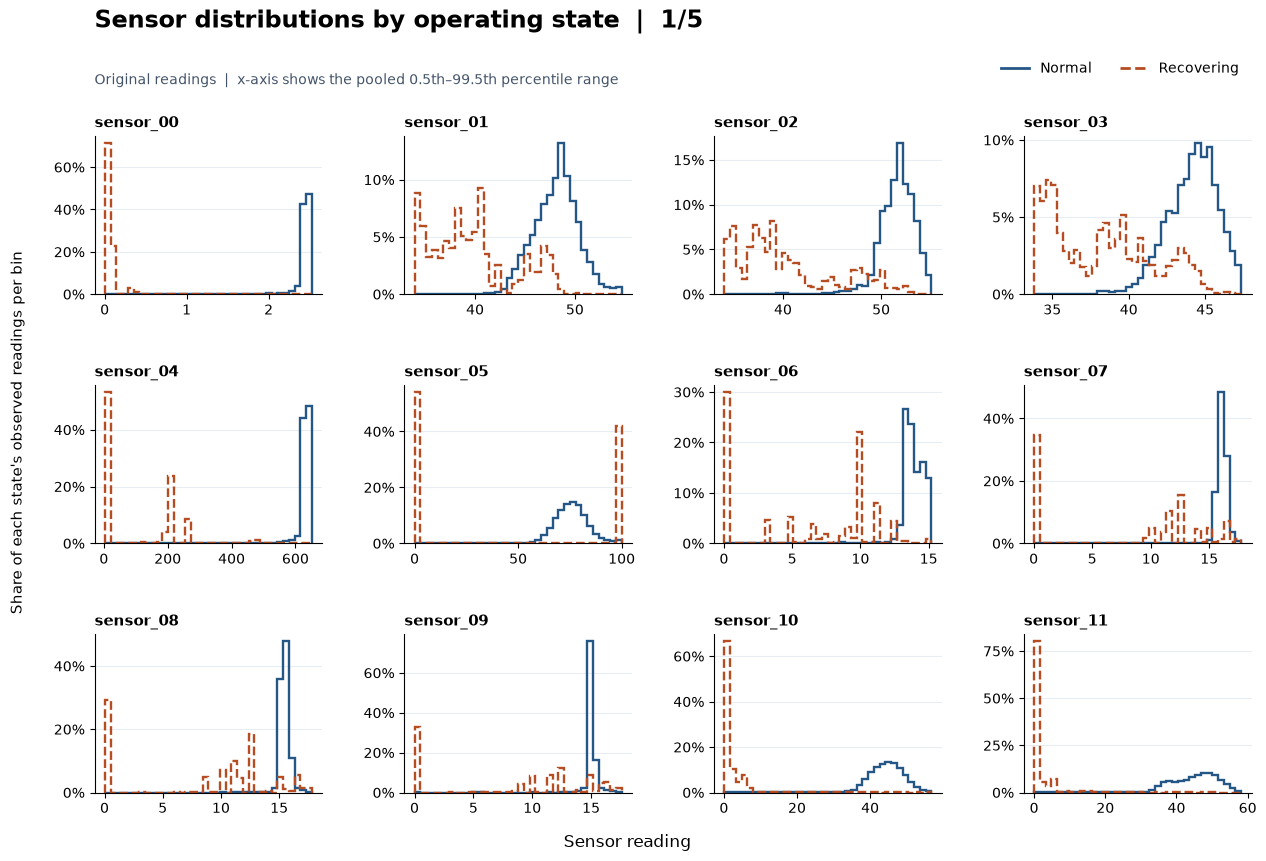

센서 분포 그래프 5개 저장


In [ ]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

plot_bounds = raw_sensors.loc[status.isin(["NORMAL", "RECOVERING"])].quantile([.005, .995])
panels_per_page = 12
distribution_paths = []
state_series = (
    (normal_readings, "Normal", "#245786", "-"),
    (recovering_readings, "Recovering", "#b54c22", "--"),
)
legend_handles = [
    Line2D([0], [0], label=label, color=color, linestyle=style, linewidth=2)
    for _, label, color, style in state_series
]
for offset in range(0, len(sensor_columns), panels_per_page):
    batch = sensor_columns[offset:offset + panels_per_page]
    page = len(distribution_paths) + 1
    fig, axes = plt.subplots(3, 4, figsize=(13, 9))
    fig.subplots_adjust(left=.09, right=.98, bottom=.10, top=.83, wspace=.36, hspace=.57)
    fig.suptitle(f"Sensor distributions by operating state  |  {page}/{(len(sensor_columns) + 11) // 12}",
                 x=.09, y=.97, ha="left", fontsize=17, fontweight="bold")
    fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(.98, .926),
               ncol=2, frameon=False)
    fig.text(.09, .887, "Original readings  |  x-axis shows the pooled 0.5th–99.5th percentile range",
             color="#43546a", fontsize=10)
    fig.supxlabel("Sensor reading", y=.035)
    fig.supylabel("Share of each state's observed readings per bin", x=.025, fontsize=11)

    for axis, sensor in zip(axes.flat, batch):
        low, high = plot_bounds[sensor]
        if low == high:
            padding = max(abs(low) * .005, .01)
            low, high = low - padding, high + padding
        bins = np.linspace(low, high, 37)
        for state_values, _, color, style in state_series:
            values = state_values[sensor].dropna().to_numpy()
            if values.size:
                counts, _ = np.histogram(values, bins=bins)
                axis.stairs(counts / values.size, bins, color=color, linestyle=style, linewidth=1.7)
        axis.set_title(sensor, loc="left", fontsize=11, fontweight="bold")
        axis.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.locator_params(axis="x", nbins=4)
        axis.locator_params(axis="y", nbins=4)
        axis.grid(axis="y", color="#e7edf3")
        axis.set_axisbelow(True)
        axis.spines[["top", "right"]].set_visible(False)
    for axis in list(axes.flat)[len(batch):]:
        axis.set_visible(False)
    output = figure_dir / f"sensor_distributions_{page:02d}.png"
    save_png(fig, output, dpi=135, facecolor="white")
    distribution_paths.append(output)
    if page == 1:
        display(fig)
    plt.close(fig)
print(f"센서 분포 그래프 {len(distribution_paths)}개 저장")

## 3. 고장 전후 패턴

원본의 `BROKEN` 시작점을 0분으로 정렬합니다. 고장 24~6시간 전의 정상 구간을 기준으로 삼고, 고장 직전 60분과 고장 후 첫 60분 중 실제 `RECOVERING` 구간을 비교합니다. 고장 후 정상 복귀 이후의 값은 회복 구간 집계에서 제외합니다.

집계는 원래 관측된 값으로 계산합니다. 각 창에서 관측 비율이 80% 미만인 센서는 그 창의 비교에서 제외합니다. 중앙값 차이는 기준 구간의 IQR로 나누며, 국소 IQR이 지나치게 작으면 전체 정상 IQR의 10%를 분모의 하한으로 씁니다. 탐색 기준으로 0.5 IQR 이상 움직인 경우의 방향이 여러 사건에서 반복되는지 확인합니다.

In [ ]:
baseline_minutes = 18 * 60
pre_minutes = 60
min_coverage = 0.80
shift_threshold = 0.50
minute = pd.Timedelta(minutes=1)
broken = status.eq("BROKEN")
event_times = timestamps.loc[broken & ~broken.shift(fill_value=False)]
status_values = status.to_numpy()

normal_quantiles = raw_sensors.loc[status.eq("NORMAL")].quantile([0.25, 0.75])
normal_scale_floor = (0.1 * (normal_quantiles.loc[0.75] - normal_quantiles.loc[0.25])).replace(0, np.nan)

event_records = []
event_sensor_records = []
for event_pos, onset in zip(np.flatnonzero(broken & ~broken.shift(fill_value=False)), event_times):
    recovery_start = event_pos + 1
    while recovery_start < len(status_values) and status_values[recovery_start] == "BROKEN":
        recovery_start += 1
    recovery_end = recovery_start
    while recovery_end < len(status_values) and status_values[recovery_end] == "RECOVERING":
        recovery_end += 1
    recovery_length = recovery_end - recovery_start
    event_records.append({
        "event": onset,
        "recovery_minutes": recovery_length,
        "recovery_start_offset": recovery_start - event_pos,
    })

    baseline_mask = (timestamps >= onset - 24 * 60 * minute) & (timestamps < onset - 6 * 60 * minute)
    pre_mask = (timestamps >= onset - pre_minutes * minute) & (timestamps < onset)
    baseline = raw_sensors.loc[baseline_mask & status.eq("NORMAL")]
    pre = raw_sensors.loc[pre_mask]
    recovery = raw_sensors.iloc[recovery_start:min(recovery_end, event_pos + pre_minutes + 1)]

    baseline_coverage = baseline.notna().sum() / baseline_minutes
    pre_coverage = pre.notna().sum() / pre_minutes
    recovery_coverage = recovery.notna().mean() if len(recovery) else pd.Series(0.0, index=sensor_columns)
    eligible_baseline = baseline_coverage.ge(min_coverage)
    eligible_pre = eligible_baseline & pre_coverage.ge(min_coverage)
    eligible_recovery = eligible_baseline & recovery_coverage.ge(min_coverage)

    baseline_median = baseline.median()
    baseline_quartiles = baseline.quantile([0.25, 0.75])
    baseline_iqr = baseline_quartiles.loc[0.75] - baseline_quartiles.loc[0.25]
    scale = baseline_iqr.clip(lower=normal_scale_floor, axis=0).replace(0, np.nan)
    pre_quartiles = pre.quantile([0.25, 0.75])
    early, late = pre.iloc[:15], pre.iloc[-15:]
    edge_coverage = early.notna().sum().ge(12) & late.notna().sum().ge(12)
    event_sensor_records.append(pd.DataFrame({
        "event": onset,
        "sensor": sensor_columns,
        "baseline_coverage": baseline_coverage,
        "pre_coverage": pre_coverage,
        "recovery_coverage": recovery_coverage,
        "pre_shift": ((pre.median() - baseline_median) / scale).where(eligible_pre),
        "pre_edge_shift": ((late.median() - early.median()) / scale).where(eligible_pre & edge_coverage),
        "pre_iqr_ratio": ((pre_quartiles.loc[0.75] - pre_quartiles.loc[0.25]) / scale).where(eligible_pre),
        "recovery_shift": ((recovery.median() - baseline_median) / scale).where(eligible_recovery),
    }))

event_catalog = pd.DataFrame(event_records).set_index("event")
event_details = pd.concat(event_sensor_records, ignore_index=True)
event_effects = event_details.pivot(index="sensor", columns="event", values="pre_shift")
event_recovery_effects = event_details.pivot(index="sensor", columns="event", values="recovery_shift")
event_summary = event_details.groupby("sensor").agg(
    valid_events=("pre_shift", "count"),
    median_pre_shift=("pre_shift", "median"),
    median_pre_edge_shift=("pre_edge_shift", "median"),
    median_pre_iqr_ratio=("pre_iqr_ratio", "median"),
    median_recovery_shift=("recovery_shift", "median"),
    valid_recovery_events=("recovery_shift", "count"),
)
event_summary["up_events"] = event_effects.ge(shift_threshold).sum(axis=1)
event_summary["down_events"] = event_effects.le(-shift_threshold).sum(axis=1)
event_summary["consistent_events"] = event_summary[["up_events", "down_events"]].max(axis=1)
event_summary["absolute_pre_shift"] = event_summary["median_pre_shift"].abs()
event_summary = event_summary.sort_values(
    ["consistent_events", "absolute_pre_shift", "valid_events"], ascending=False
)
event_ranked = event_summary.loc[event_summary["valid_events"].ge(4)]
event_picks = event_ranked.head(3).index.to_list()

display(event_catalog[["recovery_minutes"]].rename(columns={"recovery_minutes": "회복 지속(분)"}))
display(event_ranked.head(12)[[
    "valid_events", "up_events", "down_events", "median_pre_shift", "median_pre_edge_shift",
    "median_pre_iqr_ratio", "valid_recovery_events", "median_recovery_shift",
]].rename(columns={
    "valid_events": "유효 고장 수", "up_events": "고장 전 상승", "down_events": "고장 전 하락",
    "median_pre_shift": "고장 전 중앙값 변화", "median_pre_edge_shift": "직전 1시간 내 변화",
    "median_pre_iqr_ratio": "직전 1시간 변동폭 비율", "valid_recovery_events": "유효 회복 구간 수",
    "median_recovery_shift": "회복 초반 중앙값 변화",
}).round(2))

coverage_gaps = event_details.loc[event_details["pre_coverage"].lt(min_coverage),
                                  ["event", "sensor", "baseline_coverage", "pre_coverage"]]
if not coverage_gaps.empty:
    print("직전 1시간의 관측 비율이 낮았던 센서·사건")
    display(coverage_gaps.sort_values("pre_coverage").head(12).round(2))


,회복 지속(분)
event,
2018-04-12 21:55:00,944
2018-04-18 00:30:00,3110
2018-05-19 03:18:00,1312
2018-05-25 00:30:00,605
2018-06-28 22:00:00,8390
2018-07-08 00:11:00,41
2018-07-25 14:00:00,75


,유효 고장 수,고장 전 상승,고장 전 하락,고장 전 중앙값 변화,직전 1시간 내 변화,직전 1시간 변동폭 비율,유효 회복 구간 수,회복 초반 중앙값 변화
sensor,,,,,,,,
sensor_03,7,1,5,-0.76,-0.17,0.24,7,-0.68
sensor_48,7,2,5,-0.66,0.36,0.58,7,-0.06
sensor_04,7,0,4,-0.85,-0.25,1.33,7,-58.64
sensor_11,7,3,4,-0.64,-0.67,0.76,7,-12.37
sensor_06,7,2,4,-0.62,-0.03,0.29,7,-9.84
sensor_01,7,2,4,-0.59,-0.13,0.13,7,-1.05
sensor_02,7,2,4,-0.58,-0.00,0.10,7,-0.84
sensor_47,7,0,3,-0.42,0.00,0.59,7,-0.67
sensor_10,7,1,3,-0.33,-1.24,1.25,7,-7.97


### 사건별 변화량과 시계열

색상표는 기준 구간 대비 직전 60분의 중앙값 변화입니다. 표에서 순위가 높은 센서는 전체 7건의 전후 6시간 그래프를 확인합니다. 파란색은 원본 관측값, 주황색은 선형보간값, 배경 띠는 실제 회복 구간입니다. 회복이 6시간을 넘어가면 그래프는 앞 6시간까지만 표시합니다. 직전 1시간 내 변화는 마지막 15분과 첫 15분의 중앙값 차이이며, 변동폭 비율은 직전 1시간의 IQR을 기준 구간의 보정된 IQR로 나눈 값입니다.

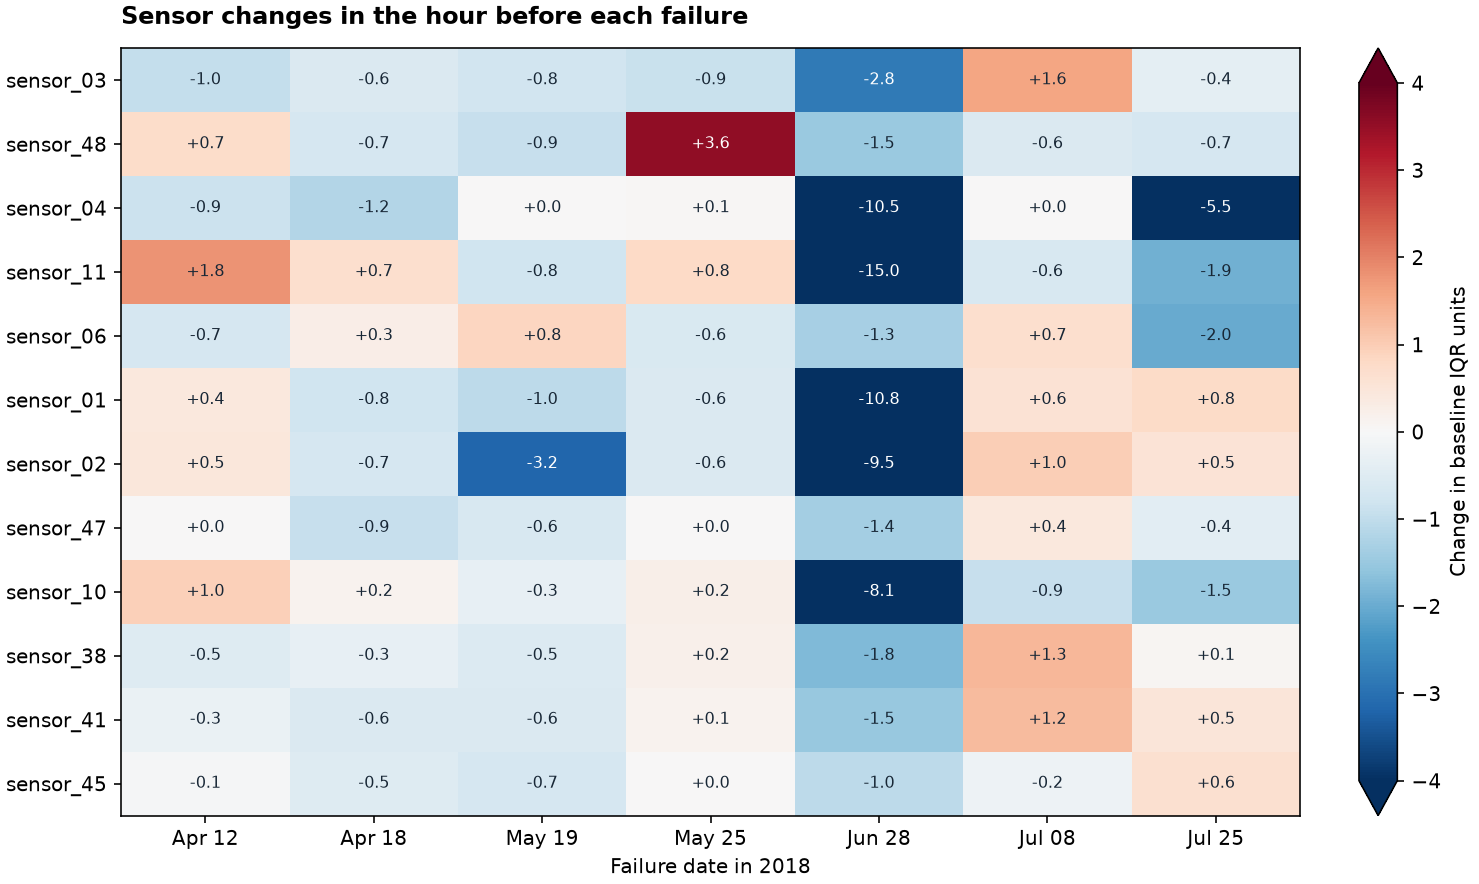

사건별 시계열 저장: event_aligned_sensor_traces.png


In [ ]:
from IPython.display import Image
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plot_effects = event_effects.loc[event_ranked.head(12).index]
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#e5eaf0")
fig, ax = plt.subplots(figsize=(10.2, 6.1), layout="constrained")
clip_limit = 4
heatmap = ax.imshow(plot_effects, cmap=cmap, vmin=-clip_limit, vmax=clip_limit, aspect="auto")
ax.set_xticks(np.arange(plot_effects.shape[1]), plot_effects.columns.strftime("%b %d"))
ax.set_yticks(np.arange(plot_effects.shape[0]), plot_effects.index)
ax.set_title("Sensor changes in the hour before each failure", loc="left", fontweight="bold", pad=12)
ax.set_xlabel("Failure date in 2018")
for i, row in enumerate(plot_effects.to_numpy()):
    for j, value in enumerate(row):
        annotation = f"{value:+.1f}" if np.isfinite(value) else "—"
        ink = "white" if np.isfinite(value) and abs(value) >= 2.5 else "#182736"
        ax.text(j, i, annotation, ha="center", va="center", color=ink, fontsize=8)
fig.colorbar(heatmap, ax=ax, label="Change in baseline IQR units", extend="both")
event_heatmap_path = figure_dir / "event_pre_failure_changes.png"
save_png(fig, event_heatmap_path, dpi=145, facecolor="white")
plt.close(fig)
display(Image(filename=str(event_heatmap_path), width=850))

observed_color, imputed_color, recovery_color = "#225f87", "#bd572b", "#dceadf"
fig, axes = plt.subplots(
    len(event_catalog), len(event_picks), figsize=(13, 13),
    sharex=True, sharey="col", squeeze=False,
)
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.06, top=0.91, hspace=0.34, wspace=0.27)
fig.suptitle("Sensor traces aligned to each pump failure", x=0.12, y=0.981, ha="left",
             fontsize=18, fontweight="bold")
legend = [
    Line2D([0], [0], color=observed_color, label="Observed"),
    Line2D([0], [0], color=imputed_color, label="Linearly imputed"),
    Line2D([0], [0], color="#263646", ls="--", label="Failure onset"),
    Patch(facecolor=recovery_color, label="Recovering"),
]
fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.113, 0.962), ncol=4, frameon=False)
for row, (onset, info) in enumerate(event_catalog.iterrows()):
    window = (timestamps >= onset - 360 * minute) & (timestamps <= onset + 360 * minute)
    relative = (timestamps.loc[window] - onset).dt.total_seconds() / 60
    recovery_start_offset = info["recovery_start_offset"]
    recovery_end_offset = min(360, recovery_start_offset + info["recovery_minutes"])
    for col, sensor in enumerate(event_picks):
        ax = axes[row, col]
        values = raw_sensors.loc[window, sensor]
        estimated = filled_sensors.loc[window, sensor].where(values.isna())
        if recovery_end_offset > recovery_start_offset:
            ax.axvspan(recovery_start_offset, recovery_end_offset, color=recovery_color, zorder=0)
        ax.plot(relative, values, color=observed_color, lw=0.9)
        ax.plot(relative, estimated, color=imputed_color, lw=1.2)
        is_imputed = estimated.notna()
        ax.scatter(relative.loc[is_imputed], estimated.loc[is_imputed], s=2,
                   color=imputed_color, linewidths=0, zorder=3)
        ax.axvline(0, color="#263646", lw=0.8, ls="--")
        ax.grid(axis="y", alpha=0.25)
        ax.set_xlim(-360, 360)
        ax.set_xticks([-360, -180, 0, 180, 360], ["−6 h", "−3 h", "0", "+3 h", "+6 h"])
        if row == 0:
            ax.set_title(sensor, loc="left", fontsize=11, fontweight="bold")
        if col == 0:
            ax.set_ylabel(onset.strftime("%b %d\n%H:%M"), rotation=0, labelpad=26, va="center")
        if row == len(event_catalog) - 1:
            ax.set_xlabel("Time relative to failure")
        ax.spines[["top", "right"]].set_visible(False)

event_traces_path = figure_dir / "event_aligned_sensor_traces.png"
save_png(fig, event_traces_path, dpi=145, facecolor="white")
plt.close(fig)
print(f"사건별 시계열 저장: {event_traces_path.name}")


## 4. 상태별 결측과 정상 대조 구간 비교

회복 중 결측이 집중되는지 확인하고, 월별 고장 수를 집계합니다. 6월 28일 고장은 회복 8,390분으로 전체 회복 14,477분의 58.0%를 차지합니다. 따라서 회복 분포를 분 단위로 합친 결과와 사건별 결과를 함께 봅니다.

In [ ]:

# 상태별 원본 관측률과 월별 고장 시작 건수
missing_cells = raw_sensors.isna()
coverage_rows = []
for state in ("NORMAL", "BROKEN", "RECOVERING"):
    group = missing_cells.loc[status.eq(state)]
    coverage_rows.append({
        "상태": state,
        "기록 행": len(group),
        "결측 센서가 있는 행": int(group.any(axis=1).sum()),
        "결측 행 비율(%)": 100 * group.any(axis=1).mean(),
        "결측 셀 비율(%)": 100 * group.to_numpy().mean(),
    })
state_coverage = pd.DataFrame(coverage_rows).set_index("상태")
display(state_coverage.round(3))

onsets = status.eq("BROKEN") & status.shift(fill_value="").ne("BROKEN")
monthly = timestamps.dt.to_period("M")
monthly_faults = onsets.groupby(monthly).sum().astype(int)
display(monthly_faults.rename("고장 시작 건수").to_frame())


,기록 행,결측 센서가 있는 행,결측 행 비율(%),결측 셀 비율(%)
상태,,,,
NORMAL,205836,769,0.374,0.016
BROKEN,7,0,0.000,0.000
RECOVERING,14477,10766,74.366,4.260


,고장 시작 건수
timestamp,
2018-04,2
2018-05,2
2018-06,1
2018-07,2
2018-08,0


### 고장 직전 변화와 평소 같은 시각의 변화 비교

각 고장과 같은 시각의 다른 날짜를 대조 구간으로 사용합니다. 전 24시간과 후 6시간이 모두 정상이고 모든 고장 시점에서 48시간 이상 떨어진 시각만 선택합니다. 고장과 대조군 모두 24~6시간 전과 직전 1시간의 센서 중앙값 차이를 구합니다. 각 센서·사건에서 유효 대조 구간 30개 이상과 두 창의 원본 관측률 80% 이상을 요구합니다.

대조 변화의 중앙값을 중심으로 절대 편차 95백분위수까지를 정상 참고 범위로 둡니다. 정상 편차가 모두 0인 비교는 제외합니다. 이 범위를 벗어난 횟수는 탐색 결과이며, 임계값과 센서 선택을 검증하려면 별도 시간 구간과 고장 사건이 필요합니다. 전체 기간의 대조값을 사용하므로 실시간 성능 지표와는 목적이 다릅니다.

In [ ]:

# 센서마다 비교할 두 구간에서 80% 이상 원래 관측값이 있을 때만 중앙값 차이를 사용합니다.
observed_values = raw_sensors.to_numpy()
fault_positions = np.flatnonzero(onsets.to_numpy())
non_normal_prefix = np.r_[0, status.ne("NORMAL").to_numpy().cumsum()]
changes = []
for fault in fault_positions:
    clock_positions = np.arange(fault % 1440, len(timestamps), 1440)
    candidates = clock_positions[(clock_positions >= 1440) & (clock_positions + 360 <= len(timestamps))]
    stable = non_normal_prefix[candidates + 360] == non_normal_prefix[candidates - 1440]
    away_from_faults = (np.abs(candidates[:, None] - fault_positions) >= 2880).all(axis=1)
    positions = np.r_[fault, candidates[stable & away_from_faults]]
    per_anchor_changes = []
    for position in positions:
        baseline = observed_values[position - 1440:position - 360]
        recent = observed_values[position - 60:position]
        eligible = (np.isfinite(baseline).mean(axis=0) >= 0.80) & (np.isfinite(recent).mean(axis=0) >= 0.80)
        median_change = np.full(len(sensor_columns), np.nan)
        median_change[eligible] = (
            np.nanmedian(recent[:, eligible], axis=0) - np.nanmedian(baseline[:, eligible], axis=0)
        )
        per_anchor_changes.append(median_change)
    change_table = pd.DataFrame(per_anchor_changes, columns=sensor_columns)
    controls = change_table.iloc[1:]
    control_center = controls.median()
    threshold = controls.sub(control_center).abs().quantile(0.95)
    observed_change = change_table.iloc[0] - control_center
    for sensor in sensor_columns:
        eligible_controls = int(controls[sensor].count())
        eligible = eligible_controls >= 30 and pd.notna(observed_change[sensor]) and threshold[sensor] > 0
        outside = bool(eligible and abs(observed_change[sensor]) > threshold[sensor])
        changes.append({
            "event": timestamps.iloc[fault], "sensor": sensor, "controls": eligible_controls,
            "offset": observed_change[sensor], "normal_limit": threshold[sensor],
            "eligible": eligible, "outside": outside,
            "up": outside and observed_change[sensor] > 0,
            "down": outside and observed_change[sensor] < 0,
        })

control_detail = pd.DataFrame(changes)
control_rank = control_detail.groupby("sensor").agg(
    eligible=("eligible", "sum"), outside=("outside", "sum"), up=("up", "sum"), down=("down", "sum"),
)
control_rank["same_direction"] = control_rank[["up", "down"]].max(axis=1)
control_rank = control_rank.sort_values(["same_direction", "outside", "eligible"], ascending=False)
display(control_rank.head(12).rename(columns={
    "eligible": "비교 가능 고장", "outside": "정상 범위 밖", "up": "증가", "down": "감소",
    "same_direction": "같은 방향 최대",
}))
print(f"대조 구간 수 {control_detail['controls'].min()}~{control_detail['controls'].max()}개")
print("대조 비교 상위", control_rank.head(5).to_dict(orient="index"))


,비교 가능 고장,정상 범위 밖,증가,감소,같은 방향 최대
sensor,,,,,
sensor_04,7,3,0,3,3
sensor_05,7,2,0,2,2
sensor_10,7,2,0,2,2
sensor_34,7,2,2,0,2
sensor_00,7,2,1,1,1
sensor_02,7,2,1,1,1
sensor_13,7,2,1,1,1
sensor_38,7,2,1,1,1
sensor_41,7,2,1,1,1


대조 구간 수 117~119개
대조 비교 상위 {'sensor_04': {'eligible': 7, 'outside': 3, 'up': 0, 'down': 3, 'same_direction': 3}, 'sensor_05': {'eligible': 7, 'outside': 2, 'up': 0, 'down': 2, 'same_direction': 2}, 'sensor_10': {'eligible': 7, 'outside': 2, 'up': 0, 'down': 2, 'same_direction': 2}, 'sensor_34': {'eligible': 7, 'outside': 2, 'up': 2, 'down': 0, 'same_direction': 2}, 'sensor_00': {'eligible': 7, 'outside': 2, 'up': 1, 'down': 1, 'same_direction': 1}}


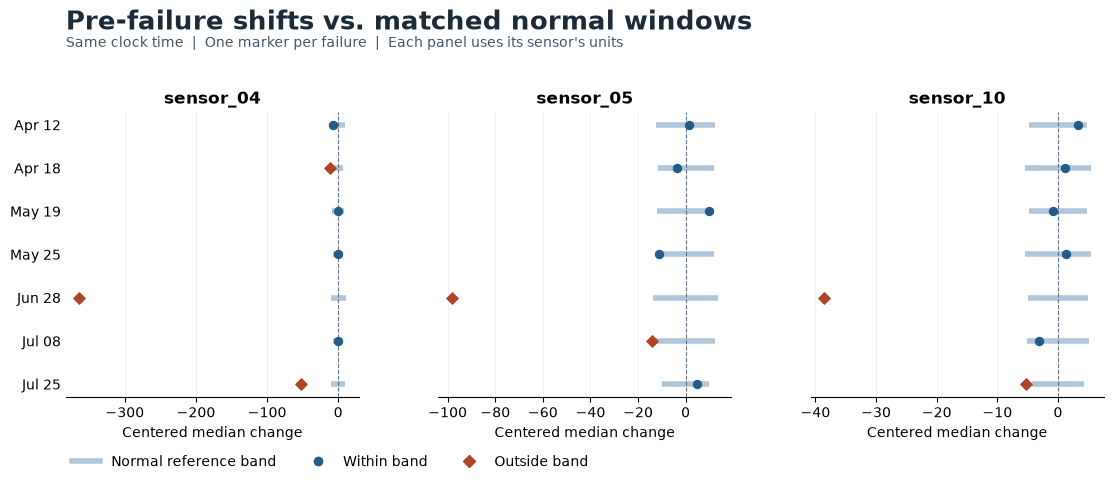

In [ ]:

picks = control_rank[control_rank["outside"] > 0].head(3).index.tolist()
if picks:
    from matplotlib.lines import Line2D
    fig, axes = plt.subplots(1, len(picks), figsize=(12, 5.0), sharey=True, squeeze=False)
    fig.subplots_adjust(left=.11, right=.975, bottom=.19, top=.76, wspace=.27)
    event_order = sorted(control_detail["event"].unique())
    for ax, sensor in zip(axes.ravel(), picks):
        d = control_detail.loc[control_detail["sensor"].eq(sensor)].set_index("event").reindex(event_order)
        for y, (_, row) in enumerate(d.iterrows()):
            if not row["eligible"]:
                ax.text(.04, y, "Insufficient data", transform=ax.get_yaxis_transform(), color="#526477", fontsize=8)
                continue
            ax.hlines(y, -row["normal_limit"], row["normal_limit"], color="#b2c6da", linewidth=4)
            ax.scatter(row["offset"], y, marker="D" if row["outside"] else "o",
                       color="#ae4529" if row["outside"] else "#245b89", s=33, zorder=3)
        ax.axvline(0, color="#64748b", linestyle="--", linewidth=.8)
        ax.set_title(sensor, fontweight="bold")
        ax.set_xlabel("Centered median change")
        ax.grid(axis="x", color="#edf1f5")
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)
    axes[0, 0].set_yticks(range(len(event_order)), [pd.Timestamp(t).strftime("%b %d") for t in event_order])
    axes[0, 0].invert_yaxis()
    fig.suptitle("Pre-failure shifts vs. matched normal windows", x=.11, y=.965, ha="left",
                 fontsize=19, fontweight="bold", color="#1d2b39")
    fig.text(.11, .89, "Same clock time  |  One marker per failure  |  Each panel uses its sensor's units", color="#42566a")
    fig.legend(handles=[
        Line2D([], [], color="#b2c6da", lw=4, label="Normal reference band"),
        Line2D([], [], color="#245b89", marker="o", ls="", label="Within band"),
        Line2D([], [], color="#ae4529", marker="D", ls="", label="Outside band"),
    ], loc="lower left", bbox_to_anchor=(.105, .02), ncol=3, frameon=False)
    output = figure_dir / "matched_normal_comparison.png"
    save_png(fig, output, dpi=145, facecolor="white")
    plt.show()
    plt.close(fig)


### 후속 모델링에서 확인할 점

고장 전용 라벨은 각 시각 이후의 정해진 예측 시간 안에 고장이 시작되는지를 표시합니다. 현재 이진 상태 라벨은 회복을 포함하므로 두 목표를 구분합니다. 기록상 8월에는 고장이 없어 8월만 사용하면 고장 탐지율을 계산할 수 없습니다. 평가 범위와 방법은 모델링 단계에서 별도로 정합니다. 고장 단위 적중 건수, 경보 선행 시간, 정상 구간의 오경보를 비교 지표로 사용할 수 있습니다. [MetroPT 고장 예측 평가 설계](https://pmc.ncbi.nlm.nih.gov/articles/PMC9747912/)